# **Business Understanding**

## **Latar Belakang**

Sebuah platform e-commerce otomotif global ingin membangun sistem pintar untuk mengestimasi harga wajar mobil bekas secara otomatis (Auto-Valuation System). Sistem ini dirancang untuk membantu pembeli dan penjual mengetahui kisaran harga pasar yang akurat berdasarkan spesifikasi fisik, usia kendaraan, riwayat servis, serta kelas harga mobil tersebut.

## **Tujuan**

1. Membangun model **Multiple Linear Regression** yang mampu memprediksi `Selling_Price` (harga jual mobil bekas dalam USD) berdasarkan spesifikasi kendaraan.

## **Masalah**

1. **Pelabelan harga masih manual** — menentukan harga wajar mobil bekas satu per satu memakan waktu dan bersifat subjektif, sementara data yang harus dinilai mencapai 5.500 baris.


## **Solusi**

Membangun sistem pintar untuk mengestimasi harga wajar mobil bekas secara otomatis (Auto-Valuation System) dengan menggunakan machine learning linear regression.

Tahapan pengerjaan:

1. **Data Preparation** — memuat dataset serta memeriksa struktur, tipe data, statistik deskriptif, nilai kosong, dan data duplikat.
2. **EDA (Exploratory Data Analysis)** — menganalisis distribusi fitur, mendeteksi outlier dengan metode IQR, dan melihat hubungan fitur terhadap target.
3. **Data Preprocessing** — imputasi missing value, capping outlier, pembuatan `Price_Category`, one-hot encoding, serta pemisahan fitur dan target.
4. **Modelling** — Multiple Linear Regression dengan **Normal Equation** yang diimplementasikan manual memakai NumPy.
5. **Evaluation** — menghitung R2, Adjusted R2, MAE, MSE, dan RMSE secara manual.
6. **GUI** — membangun antarmuka Tkinter untuk prediksi harga mobil bekas.

In [2]:
# ============================================================
# Import Library
# ============================================================
# Fungsi      : memuat seluruh library yang dipakai sepanjang notebook
#               - pandas     : membaca dan mengolah data tabular
#               - numpy      : komputasi numerik (matriks, statistik)
#               - matplotlib : membuat grafik
#               - seaborn    : mempercantik grafik statistik
#               - tkinter    : membangun antarmuka GUI prediksi
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tkinter as tk

# Kesimpulan  : seluruh library berhasil dimuat, sehingga tahap berikutnya
#               dapat dijalankan tanpa error ModuleNotFoundError.

In [3]:
# ============================================================
# Data Preparation - Memuat Dataset
# ============================================================
# Fungsi      : membaca file dataset/automobile_dataset.csv ke dalam DataFrame df
df = pd.read_csv('dataset/automobile_dataset.csv')

# Kesimpulan  : dataset berhasil dimuat ke variabel df dan siap diperiksa
#               pada sel-sel berikutnya.

## **Data Preparation**

Tahap pengumpulan dan penyiapan data awal: memuat dataset, memeriksa struktur (jumlah baris dan kolom), tipe data, statistik deskriptif, nilai kosong, serta data duplikat.

In [4]:
# ============================================================
# Data Preparation - Dimensi Dataset dan Cuplikan Data
# ============================================================
# Fungsi      : menampilkan jumlah baris, jumlah kolom, jumlah entri, dan 5 baris
#               pertama untuk mengenali bentuk data secara sekilas
print('Menampilkan jumlah baris pada dataset : \n', df.shape[0])
print('========================================================')
print('Menampilkan jumlah kolom pada dataset : \n', df.shape[1])
print('========================================================')
print('Menampilkan jumlah entri pada dataset : \n')
print(df.size)
df.head()

# Kesimpulan  : dataset berisi 5.500 baris dan 18 kolom (99.000 entri), terdiri atas
#               9 kolom numerik dan 9 kolom kategorikal (bertipe object).

Menampilkan jumlah baris pada dataset : 
 5500
Menampilkan jumlah kolom pada dataset : 
 18
Menampilkan jumlah entri pada dataset : 

99000


,Make,Model,Year,Fuel_Type,Transmission,Engine_Size,Mileage,Horsepower,Torque,Owners,Accident_History,Service_History,Color,Body_Type,Drivetrain,Fuel_Efficiency,Location,Selling_Price
0,Mercedes-Benz,GLE,2024,Petrol,Automatic,2.3,100,186.0,196.0,1,0.0,NaN,Silver,SUV,AWD,30.0,IL,64140
1,Hyundai,Tucson,2008,Petrol,Automatic,2.3,387035,189.0,190.0,4,0.0,NaN,Blue,SUV,FWD,35.0,FL,500
2,Volkswagen,Golf,2021,Hybrid,NaN,1.9,46054,158.0,153.0,1,0.0,Partial Service,Gray,Hatchback,AWD,43.0,NY,16429
3,Chevrolet,Tahoe,2005,Petrol,NaN,2.2,141302,169.0,165.0,5,1.0,No Service,Blue,SUV,AWD,NaN,FL,2199
4,Toyota,Camry,2022,Petrol,Automatic,1.9,32813,149.0,141.0,1,0.0,Full Service,Brown,Sedan,FWD,38.0,CA,21792


In [5]:
# ============================================================
# Data Preparation - Tipe Data dan Statistik Deskriptif
# ============================================================
# Fungsi      : memeriksa tipe data dan jumlah nilai non-null tiap kolom (df.info())
#               serta melihat ringkasan statistik kolom numerik (df.describe())
print('Menampilkan informasi dataset : \n', df.info())
print('========================================================')
print('Menampilkan deskripsiif dataset : \n', df.describe())
print('========================================================')

# Kesimpulan  : tidak ada kolom yang salah tipe data (numerik sudah terbaca int64/float64).
#               df.describe() memperlihatkan rentang nilai yang lebar, misalnya Mileage
#               100 - 536.731 dan Selling_Price 500 - 86.692, yang menandakan adanya
#               pencilan (outlier).

<class 'pandas.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Make              5500 non-null   str    
 1   Model             5500 non-null   str    
 2   Year              5500 non-null   int64  
 3   Fuel_Type         5500 non-null   str    
 4   Transmission      4673 non-null   str    
 5   Engine_Size       4656 non-null   float64
 6   Mileage           5500 non-null   int64  
 7   Horsepower        4700 non-null   float64
 8   Torque            4701 non-null   float64
 9   Owners            5500 non-null   int64  
 10  Accident_History  4688 non-null   float64
 11  Service_History   4645 non-null   str    
 12  Color             4697 non-null   str    
 13  Body_Type         5500 non-null   str    
 14  Drivetrain        5500 non-null   str    
 15  Fuel_Efficiency   4706 non-null   float64
 16  Location          4718 non-null   str    
 17  Sellin

In [6]:
# ============================================================
# Data Preparation - Pemeriksaan Nilai Kosong
# ============================================================
# Fungsi      : menghitung jumlah nilai kosong pada setiap kolom dan total keseluruhan
print('nilai kosong pada dataset : ', df.isnull().sum())
print('========================================================')
print('nilai kosong pada dataset : ', df.isnull().sum().sum())

# Kesimpulan  : terdapat 7.316 nilai kosong yang tersebar pada 9 kolom, terbanyak pada
#               Service_History (855) dan Transmission (827). Nilai kosong ini harus
#               ditangani sebelum data dianalisis dan dilatih.

nilai kosong pada dataset :  Make                  0
Model                 0
Year                  0
Fuel_Type             0
Transmission        827
Engine_Size         844
Mileage               0
Horsepower          800
Torque              799
Owners                0
Accident_History    812
Service_History     855
Color               803
Body_Type             0
Drivetrain            0
Fuel_Efficiency     794
Location            782
Selling_Price         0
dtype: int64
nilai kosong pada dataset :  7316


In [25]:
# ============================================================
# Data Preparation - Penanganan Missing Value
# ============================================================
# Fungsi      : menangani seluruh nilai kosong pada dataset
#               - Engine_Size = 0 dianggap data tidak wajar (127 baris), diubah jadi NaN
#               - kolom numerik     -> diisi dengan median (tahan terhadap outlier)
#               - kolom kategorikal -> diisi dengan modus (nilai paling sering muncul)
#               Median dan modus dipakai karena data belum terbukti berdistribusi normal.

# Nilai tidak wajar: ukuran mesin 0 dianggap data hilang, lalu diimputasi
df.loc[df['Engine_Size'] == 0, 'Engine_Size'] = np.nan

kolom_numerik = df.select_dtypes(include=['number']).columns
kolom_kategorik = df.columns.difference(kolom_numerik)

# imputasi kolom numerik dengan median
for col in kolom_numerik:
    df[col] = df[col].fillna(df[col].median())

# imputasi kolom kategorik dengan modus
for col in kolom_kategorik:
    df[col] = df[col].fillna(df[col].mode()[0])

print('Total nilai kosong setelah penanganan :', df.isnull().sum().sum())
print('========================================================')
print(df.isnull().sum())

# Kesimpulan  : seluruh 7.316 nilai kosong berhasil diimputasi dan 127 nilai Engine_Size
#               yang tidak wajar sudah digantikan median (df.isnull().sum().sum() = 0),
#               sehingga dataset bersih dari missing value tanpa mengurangi jumlah baris.

Total nilai kosong setelah penanganan : 0
Make                0
Model               0
Year                0
Fuel_Type           0
Transmission        0
Engine_Size         0
Mileage             0
Horsepower          0
Torque              0
Owners              0
Accident_History    0
Service_History     0
Color               0
Body_Type           0
Drivetrain          0
Fuel_Efficiency     0
Location            0
Selling_Price       0
Price_Category      0
dtype: int64


In [8]:
# ============================================================
# Data Preparation - Pemeriksaan Data Duplikat
# ============================================================
# Fungsi      : menghitung jumlah baris yang identik (duplikat) pada dataset
print('nilai duplikat pada dataset : ', df.duplicated().sum())

# Kesimpulan  : tidak ditemukan baris duplikat (0 baris), sehingga tidak ada data yang
#               perlu dihapus dan seluruh 5.500 baris tetap dipakai.

nilai duplikat pada dataset :  0


## **EDA (Exploratory Data Analysis)**

Analisis eksploratif untuk melihat distribusi fitur, mendeteksi outlier, serta mengamati hubungan antar fitur dan hubungan fitur terhadap target `Selling_Price`.

In [9]:
# ============================================================
# EDA - Deteksi Outlier dengan Metode IQR
# ============================================================
# Fungsi      : menghitung batas bawah (Q1 - 1.5*IQR) dan batas atas (Q3 + 1.5*IQR)
#               untuk setiap kolom numerik, lalu merekap jumlah outlier tiap kolom.
#               Batas yang dihitung di sini akan dipakai kembali pada sel capping.
cols = df.select_dtypes(include=['int64', 'float64'])

Q1 = cols.quantile(0.25)
Q3 = cols.quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = ((cols < batas_bawah) | (cols > batas_atas)).sum()
# print('outlier pada dataset : \n', outlier)
# print('========================================================')
# print('Total outlier : ', outlier.sum())

hasil = pd.DataFrame({'Jumlah Outlier': outlier, 'Persetase Outlier': (outlier/len(df))*100})
hasil.sort_values(by = 'Jumlah Outlier', ascending = False )

# Kesimpulan  : outlier terdeteksi pada beberapa kolom numerik, yaitu 1.166 nilai pada
#               fitur (di luar kolom target) dan 144 nilai pada Selling_Price.
#               Karena nilainya masih wajar secara bisnis dan jumlah baris terbatas,
#               outlier akan ditangani dengan capping, bukan dihapus.

,Jumlah Outlier,Persetase Outlier
Fuel_Efficiency,408,7.418182
Torque,261,4.745455
Horsepower,226,4.109091
Engine_Size,217,3.945455
Selling_Price,144,2.618182
Mileage,54,0.981818
Year,0,0.000000
Accident_History,0,0.000000
Owners,0,0.000000


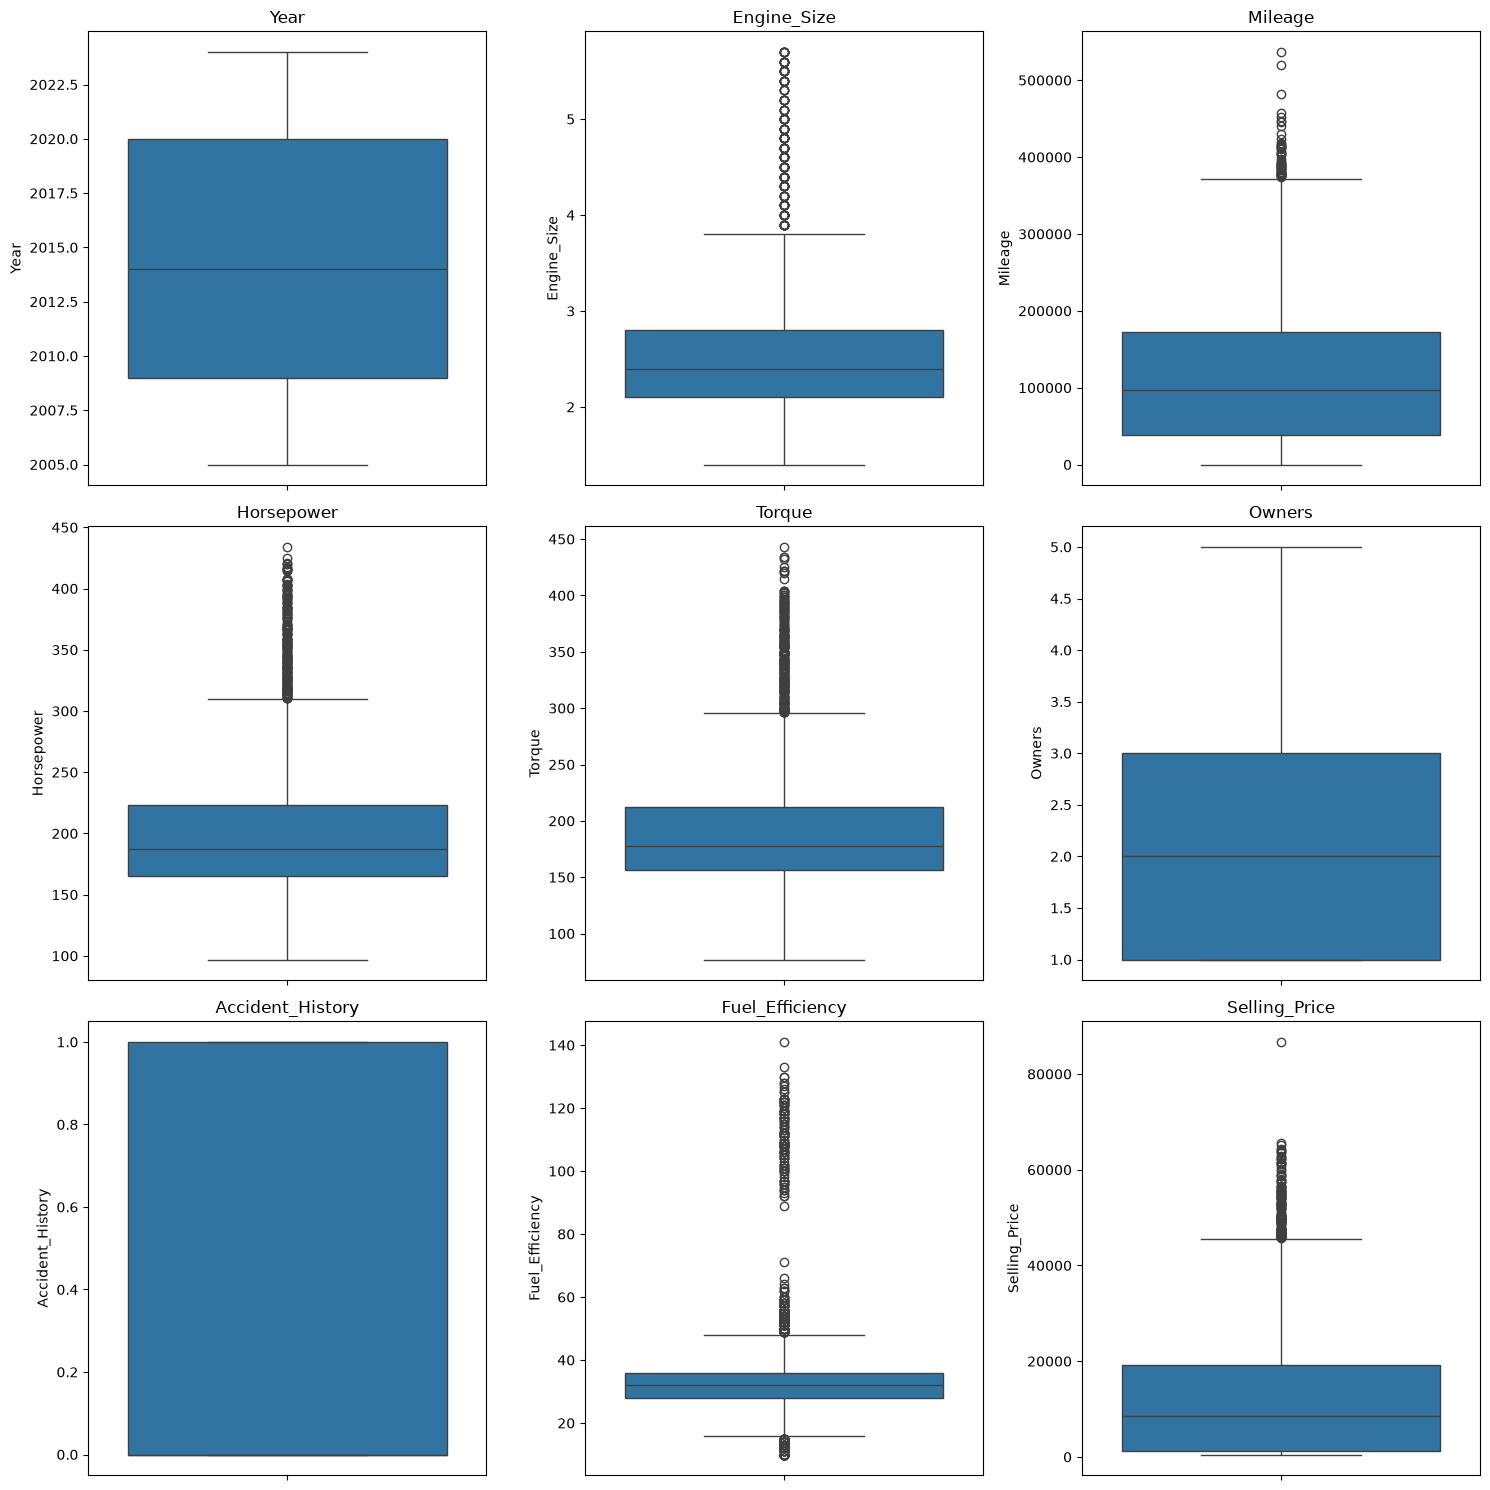

In [10]:
# ============================================================
# EDA - Visualisasi Boxplot Fitur Numerik
# ============================================================
# Fungsi      : menampilkan boxplot setiap kolom numerik dalam satu figure 3x3 untuk
#               melihat sebaran data serta posisi outlier secara visual.
#               enumerate(..., start=1) dipakai agar indeks subplot berupa angka.
plt.figure(figsize=(15,15))

for i, col in enumerate(cols, start=1):
    plt.subplot(3, 3, i)
    sns.boxplot(data=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

# Kesimpulan  : hampir semua boxplot memperlihatkan titik di luar whisker, terutama pada
#               Mileage, Torque, dan Selling_Price. Hal ini membenarkan hasil perhitungan
#               IQR sebelumnya bahwa penanganan outlier memang diperlukan.

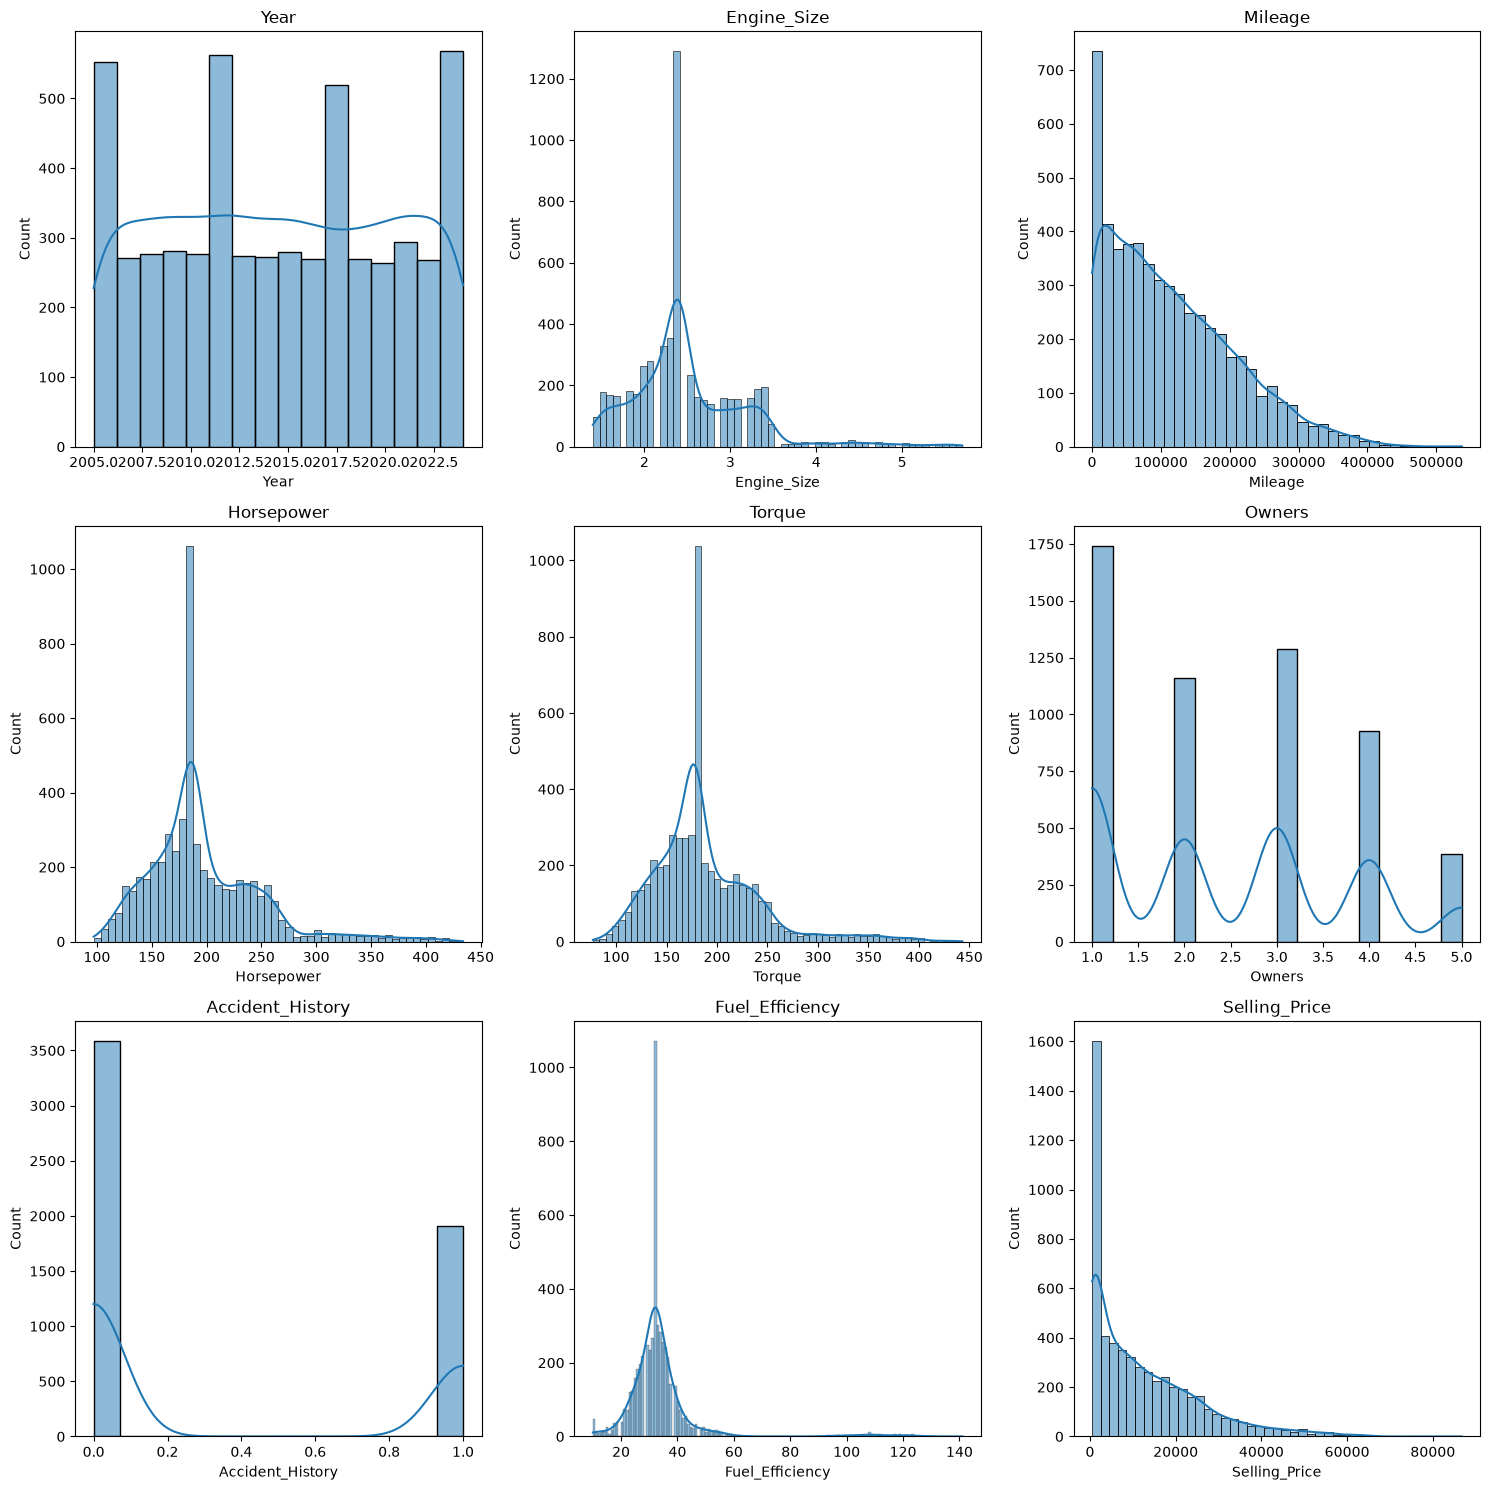

In [11]:
# ============================================================
# EDA - Histogram Distribusi Fitur Numerik
# ============================================================
# Fungsi      : menampilkan histogram beserta kurva KDE tiap kolom numerik untuk melihat
#               bentuk distribusi data (normal, miring, atau seragam)
kolom = df.select_dtypes(include=['number'])

plt.figure(figsize=(15, 15))

for i, col in enumerate(kolom, start=1):
    plt.subplot(3, 3, i)
    sns.histplot(data=df[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

# Kesimpulan  : sebagian besar fitur numerik berdistribusi miring (skewed) dan tidak
#               normal, misalnya Selling_Price, Mileage, dan Torque. Karena itu statistik
#               median dipakai saat imputasi dan capping IQR diterapkan pada tahap
#               penanganan outlier.

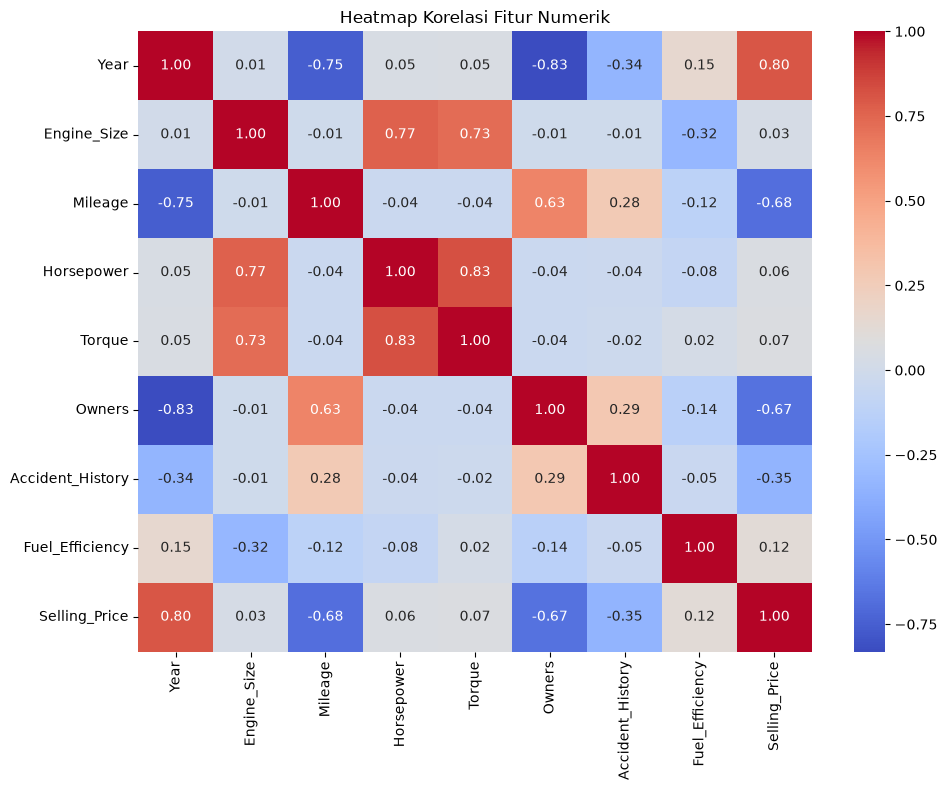

In [12]:
# ============================================================
# EDA - Heatmap Korelasi Fitur Numerik
# ============================================================
# Fungsi      : menghitung matriks korelasi antar kolom numerik lalu menampilkannya
#               sebagai heatmap untuk melihat arah dan kekuatan hubungan antar fitur
# Korelasi antar fitur numerik dan target Selling_Price
plt.figure(figsize=(10, 8))

sns.heatmap(df.select_dtypes(include=['number']).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Heatmap Korelasi Fitur Numerik')
plt.tight_layout()
plt.show()

# Kesimpulan  : Year berkorelasi positif paling kuat terhadap Selling_Price (+0.81),
#               sedangkan Mileage (-0.68), Owners (-0.67), dan Accident_History (-0.39)
#               berkorelasi negatif. Fitur lain seperti Engine_Size, Horsepower, Torque,
#               dan Fuel_Efficiency korelasinya lemah (di bawah 0.13).

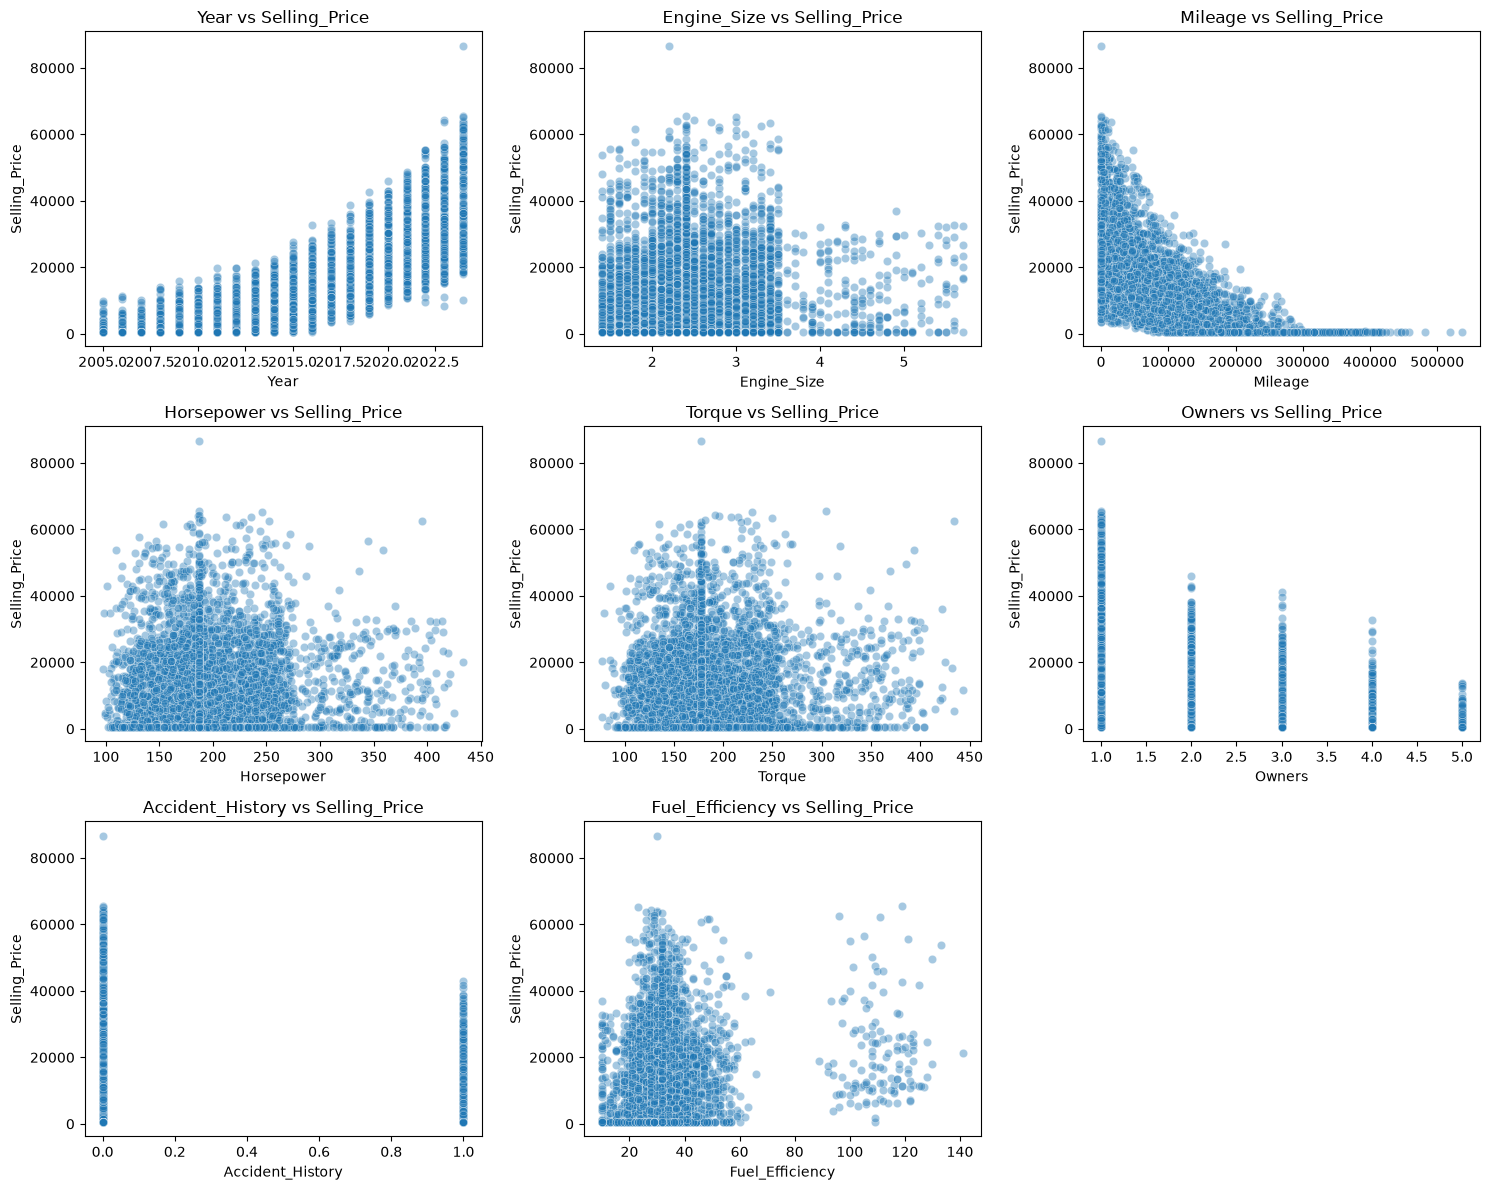

In [13]:
# ============================================================
# EDA - Scatter Plot Fitur Numerik terhadap Target
# ============================================================
# Fungsi      : memeriksa asumsi linearitas antara setiap fitur numerik dan target
#               Selling_Price melalui scatter plot
# Hubungan tiap fitur numerik terhadap Selling_Price (cek asumsi linearitas)
fitur_numerik = ['Year', 'Engine_Size', 'Mileage', 'Horsepower', 'Torque',
                 'Owners', 'Accident_History', 'Fuel_Efficiency']

plt.figure(figsize=(15, 12))

for i, col in enumerate(fitur_numerik, start=1):
    plt.subplot(3, 3, i)
    sns.scatterplot(data=df, x=col, y='Selling_Price', alpha=0.4)
    plt.title(f'{col} vs Selling_Price')

plt.tight_layout()
plt.show()

# Kesimpulan  : Year memperlihatkan kecenderungan linear positif dan Mileage linear
#               negatif, sedangkan fitur lain polanya lebih menyebar. Pola ini mendukung
#               pemakaian regresi linear, meskipun besar pengaruh tiap fitur berbeda.

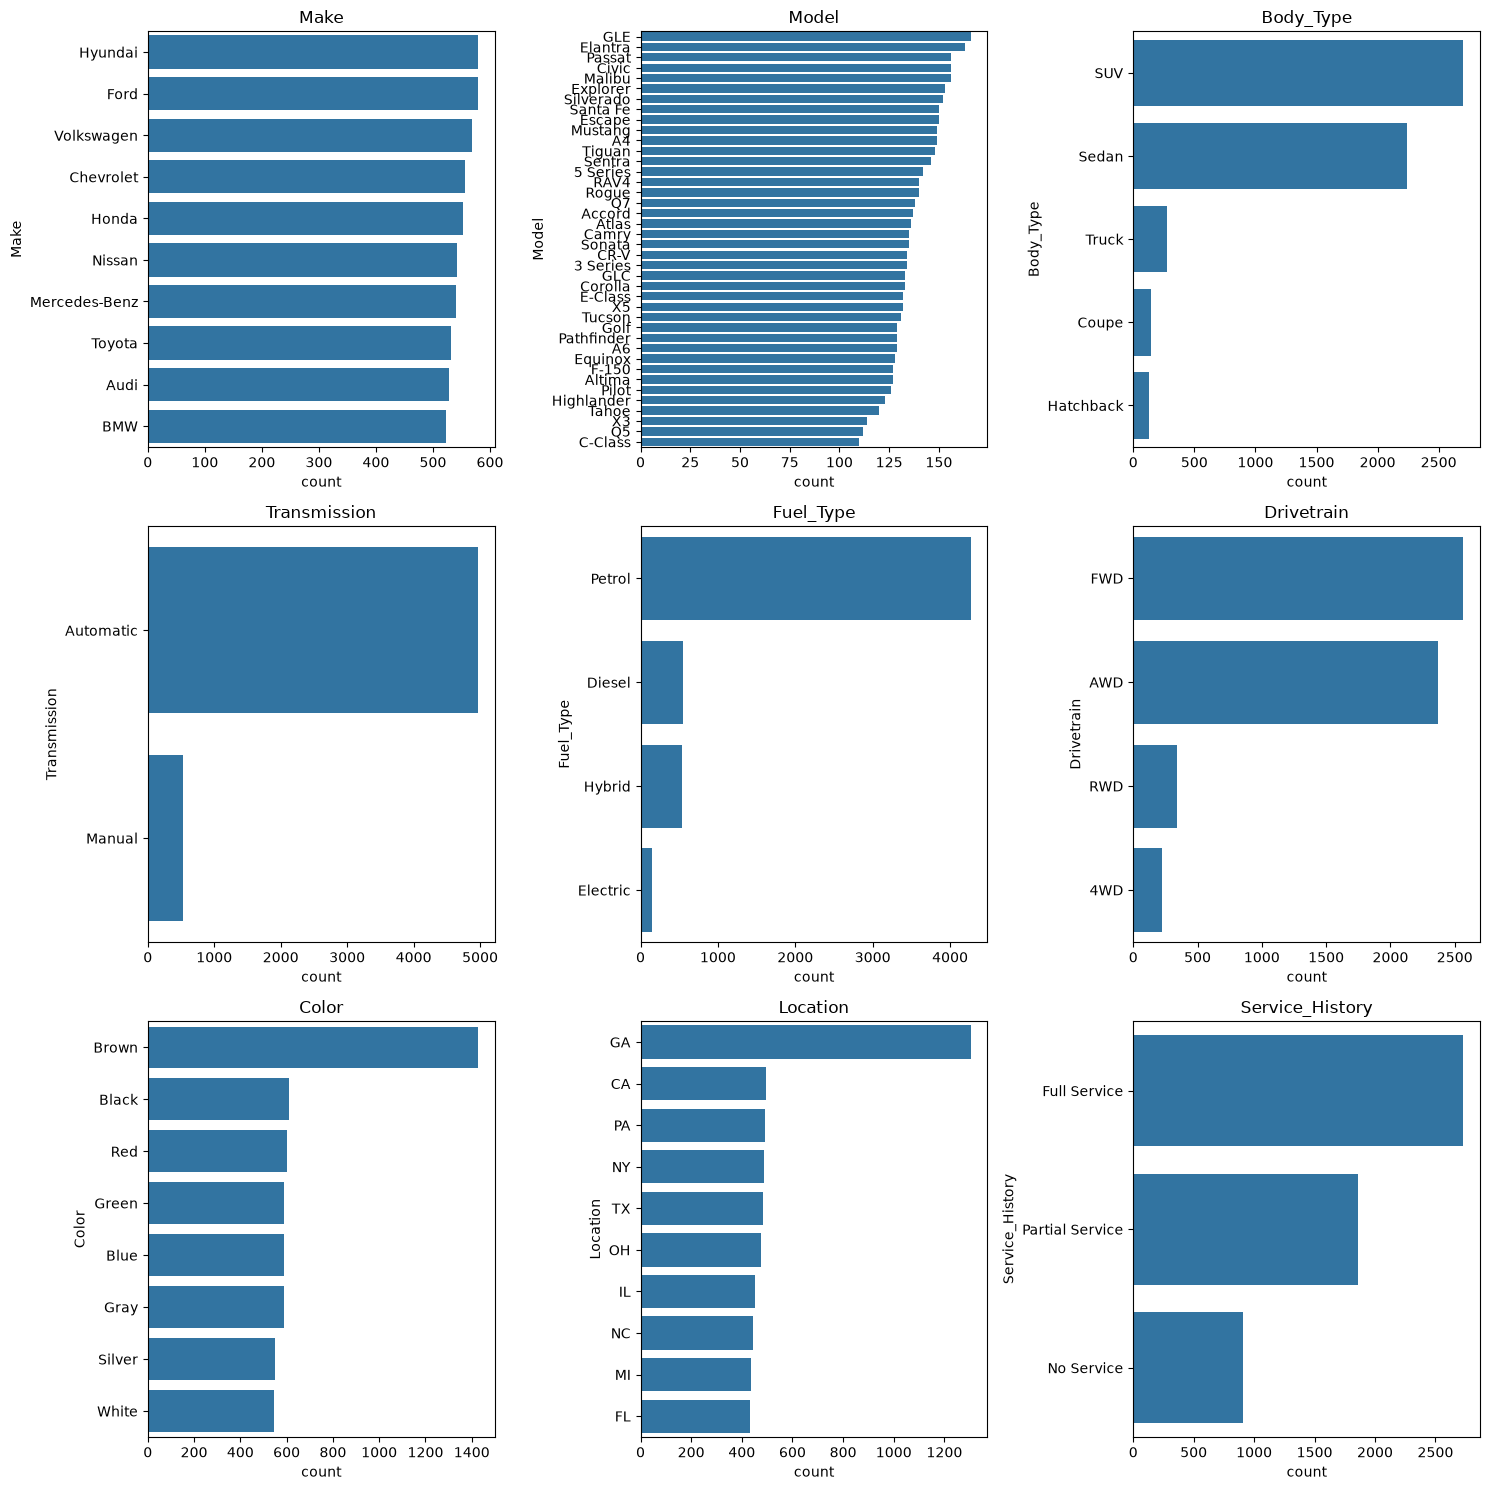

In [ ]:
# ============================================================
# EDA - Distribusi Fitur Kategorikal
# ============================================================
# Fungsi      : menampilkan countplot tiap fitur kategorikal untuk melihat sebaran
#               frekuensi antar kategori
# Distribusi tiap fitur kategorikal
fitur_kategorik = ['Make', 'Model', 'Body_Type', 'Transmission', 'Fuel_Type',
                   'Drivetrain', 'Color', 'Location', 'Service_History']

plt.figure(figsize=(15, 15))

for i, col in enumerate(fitur_kategorik, start=1):
    plt.subplot(3, 3, i)
    sns.countplot(data=df, y=col, order=df[col].value_counts().index)
    plt.title(col)

plt.tight_layout()  
plt.show()

# Kesimpulan  : distribusi kategori tidak seimbang; beberapa merek dan model sangat
#               dominan sementara kategori lain jumlahnya sedikit. Karena itu jumlah
#               kolom dummy hasil one-hot encoding nanti cukup banyak, yaitu 77 kolom.

In [15]:
# ============================================================
# EDA - Penanganan Outlier: IQR (Winsorizing / Capping)
# ============================================================
# Fungsi      : menarik nilai ekstrem setiap fitur numerik ke batas IQR terdekat
#               (capping / winsorizing) tanpa menghapus baris.
#               Outlier tidak dihapus karena nilai ekstrem (mis. Mileage tinggi pada
#               mobil tua) masih valid dan penting sebagai sinyal harga.
#               Catatan: kolom target Selling_Price TIDAK di-capping agar variasi
#               harga asli tetap utuh untuk model regresi.

kolom_capping = cols.columns.drop('Selling_Price')
batas_bawah_cap = batas_bawah[kolom_capping]
batas_atas_cap = batas_atas[kolom_capping]

outlier_sebelum = ((df[kolom_capping] < batas_bawah_cap) | (df[kolom_capping] > batas_atas_cap)).sum()

for col in kolom_capping:
    df[col] = df[col].clip(lower=batas_bawah_cap[col], upper=batas_atas_cap[col])

outlier_sesudah = ((df[kolom_capping] < batas_bawah_cap) | (df[kolom_capping] > batas_atas_cap)).sum()

ringkasan = pd.DataFrame({
    'Outlier Sebelum': outlier_sebelum,
    'Outlier Sesudah': outlier_sesudah
})

print('Total outlier sebelum capping :', outlier_sebelum.sum())
print('Total outlier sesudah capping :', outlier_sesudah.sum())
print('========================================================')
print(ringkasan)

# Kesimpulan  : jumlah outlier pada fitur numerik turun dari 1.166 menjadi 0, sementara
#               jumlah baris tetap 5.500 dan rentang harga asli (500 - 86.692 USD)
#               tidak berubah karena kolom target tidak ikut di-capping.

Total outlier sebelum capping : 1166
Total outlier sesudah capping : 0
                  Outlier Sebelum  Outlier Sesudah
Year                            0                0
Engine_Size                   217                0
Mileage                        54                0
Horsepower                    226                0
Torque                        261                0
Owners                          0                0
Accident_History                0                0
Fuel_Efficiency               408                0


## **Data Preprocessing**

Tahap menyiapkan data agar siap dilatih model:

1. **Pembuatan kelas target** — membentuk `Price_Category` dari `Selling_Price`:
   - **Low**: harga kurang dari sama dengan $5.000
   - **Medium**: harga $5.001 - $20.000
   - **High**: harga lebih dari $20.000
2. **One-Hot Encoding** — mengubah 9 kolom kategorikal menjadi kolom dummy 0/1 dengan `drop_first=True` agar terhindar dari *dummy variable trap*.
3. **Pemisahan fitur dan target** — `X` berisi seluruh fitur hasil encoding, `y` berisi `Selling_Price`.

In [16]:
# ============================================================
# Data Preprocessing - Pembuatan Kelas Target Price_Category
# ============================================================
# Fungsi      : membentuk kelas target baru Price_Category dari Selling_Price memakai
#               pd.cut dengan tiga kelas:
#               - Low    : harga kurang dari sama dengan $5.000
#               - Medium : harga $5.001 - $20.000
#               - High   : harga lebih dari $20.000
# Membuat kelas target Price_Category dari Selling_Price
df['Price_Category'] = pd.cut(
    df['Selling_Price'],
    bins=[-np.inf, 5000, 20000, np.inf],
    labels=['Low', 'Medium', 'High']
)

print('Distribusi Price_Category :')
print('========================================================')
print(df['Price_Category'].value_counts())

# Kesimpulan  : ketiga kelas terbentuk dengan jumlah Medium 2.125, Low 2.091, dan
#               High 1.284 baris. Distribusinya cukup merata, meskipun kelas High paling
#               sedikit karena harga di atas $20.000 memang lebih jarang.

Distribusi Price_Category :
Price_Category
Medium    2125
Low       2091
High      1284
Name: count, dtype: int64


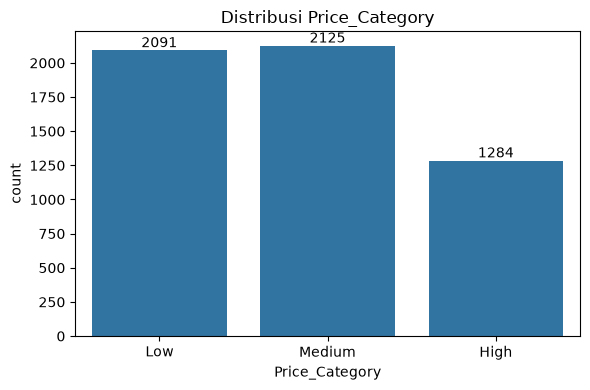

In [17]:
# ============================================================
# Data Preprocessing - Visualisasi Distribusi Price_Category
# ============================================================
# Fungsi      : menampilkan jumlah anggota tiap kelas Price_Category dalam bentuk bar
#               chart beserta label angkanya (bar_label)
# Visualisasi distribusi kelas target Price_Category
plt.figure(figsize=(6, 4))

ax = sns.countplot(data=df, x='Price_Category', order=['Low', 'Medium', 'High'])
ax.bar_label(ax.containers[0])
plt.title('Distribusi Price_Category')
plt.tight_layout()
plt.show()

# Kesimpulan  : kelas Low, Medium, dan High terisi cukup merata (1.284 - 2.125 baris),
#               sehingga kelas target ini layak dipakai untuk analisis klasifikasi
#               tanpa perlu penyeimbangan data.

In [18]:
# ============================================================
# Data Preprocessing - Encoding Fitur Kategorikal (One-Hot, tanpa sklearn)
# ============================================================
# Fungsi      : mengubah seluruh kolom kategorikal menjadi kolom dummy berisi 0/1
#               memakai pd.get_dummies.
#               - drop_first=True : mencegah dummy variable trap (multikolinearitas
#                 sempurna) pada regresi linear.
#               - dtype=int       : hasil dummy berupa bilangan bulat 0/1.
#               Kolom Price_Category dikecualikan karena merupakan target, bukan fitur.

kolom_kategorik_enc = df.select_dtypes(exclude=['number']).columns.drop('Price_Category')

df_encoded = pd.get_dummies(df, columns=kolom_kategorik_enc, drop_first=True, dtype=int)

print('Jumlah kolom sebelum encoding :', df.shape[1])
print('Jumlah kolom sesudah encoding :', df_encoded.shape[1])

# Kesimpulan  : 9 kolom kategorikal dipecah menjadi 77 kolom dummy sehingga jumlah kolom
#               bertambah dari 19 menjadi 87. Seluruh data kini bertipe numerik dan siap
#               diproses model regresi.

Jumlah kolom sebelum encoding : 19
Jumlah kolom sesudah encoding : 87


In [19]:
# ============================================================
# Data Preprocessing - Pemisahan Fitur (X) dan Target (y)
# ============================================================
# Fungsi      : memisahkan variabel bebas dan variabel terikat
#               - X = seluruh fitur hasil encoding (Selling_Price dan Price_Category dibuang)
#               - y = Selling_Price, yaitu target yang diprediksi model regresi

X = df_encoded.drop(columns=['Selling_Price', 'Price_Category'])
y = df_encoded['Selling_Price']

print('Ukuran X :', X.shape)
print('Ukuran y :', y.shape)

# Kesimpulan  : diperoleh X berukuran (5.500, 85) dan y berukuran (5.500,), sehingga data
#               siap dibagi menjadi data train dan data test pada tahap modelling.

Ukuran X : (5500, 85)
Ukuran y : (5500,)


## **Modelling (Multiple Linear Regression)**

Model regresi linear berganda dilatih **secara manual tanpa sklearn** menggunakan **Normal Equation**:

> **beta = (X'X)^-1 X'y**

Karena antar kolom dummy saling berkolinear (matriks `X'X` singular, rank 73 dari 86 kolom), perhitungan memakai **pseudo-inverse** (`np.linalg.pinv`) agar solusi tetap stabil. Data dibagi menjadi train (80%) dan test (20%).

In [20]:
# ============================================================
# Modelling - Pembagian Data Train dan Test
# ============================================================
# 1. Bagi data menjadi train (80%) dan test (20%) secara manual
#    Fungsi: mengacak indeks data memakai np.random.permutation dengan seed 42 agar hasil
#            dapat direproduksi, lalu memakai 80% data pertama sebagai train dan 20%
#            sisanya sebagai test.
np.random.seed(42)
indeks = np.random.permutation(len(X))
n_train = int(0.8 * len(X))

idx_train = indeks[:n_train]
idx_test = indeks[n_train:]

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]

print(f'Jumlah data train: {len(X_train)}')
print(f'Jumlah data test: {len(X_test)}')

# Kesimpulan  : diperoleh 4.400 baris data train dan 1.100 baris data test yang saling
#               lepas (tidak ada baris yang masuk ke dua himpunan sekaligus), sehingga
#               evaluasi model tetap valid dan tidak terjadi data leakage.

Jumlah data train: 4400
Jumlah data test: 1100


In [21]:
# ============================================================
# Modelling - Multiple Linear Regression (Normal Equation)
# ============================================================

# 2. Standardisasi fitur (z-score) memakai statistik data train saja
#    Fungsi: menyetarakan skala antar fitur dengan rumus (x - mu) / sigma.
#            mu dan sigma dihitung dari X_train saja supaya data test tidak "bocor"
#            (data leakage). Nilai sigma 0 diganti 1 agar tidak terjadi pembagian nol.
mu = X_train.mean().values
sigma = X_train.std(ddof=0).to_numpy(dtype=float, copy=True)
sigma[sigma == 0] = 1

X_train_const = np.c_[np.ones(len(X_train)), (X_train.values - mu) / sigma]
X_test_const = np.c_[np.ones(len(X_test)), (X_test.values - mu) / sigma]

# 3. Hitung koefisien dengan Normal Equation: beta = (X'X)^-1 X'y
#    Fungsi: mencari koefisien regresi yang meminimalkan jumlah kuadrat error (OLS).
#    Karena X'X singular (rank 73 dari 86 kolom) akibat multikolinearitas antar kolom
#    dummy, dipakai pseudo-inverse agar solusinya tetap stabil dan tunggal.
beta = np.linalg.pinv(X_train_const.T @ X_train_const) @ X_train_const.T @ y_train.values

# 4. Lakukan prediksi
#    Fungsi: menghitung harga prediksi pada data train dan data test dengan y = X * beta
y_pred_train = X_train_const @ beta
y_pred_test = X_test_const @ beta

print('Jumlah data train :', len(X_train))
print('Jumlah data test  :', len(X_test))
print('Jumlah koefisien  :', len(beta))
print('Intercept (beta0) :', round(beta[0], 2))

# Kesimpulan  : model terbentuk dari 86 koefisien (1 intercept + 85 fitur) dengan
#               intercept 12.488,85, tepat sama dengan rata-rata harga pada data train
#               karena fitur sudah distandarisasi. Nilai beta inilah yang dipakai untuk
#               perhitungan metrik evaluasi dan aplikasi GUI.

Jumlah data train : 4400
Jumlah data test  : 1100
Jumlah koefisien  : 86
Intercept (beta0) : 12488.85


## **Evaluation**

Performa model diukur pada data test memakai metrik yang dihitung manual dengan NumPy: **R2**, **Adjusted R2**, **MAE**, **MSE**, dan **RMSE**.

In [22]:
# ============================================================
# Evaluation - Perhitungan Metrik secara Manual (tanpa sklearn)
# ============================================================
# Fungsi      : menghitung metrik evaluasi regresi murni dengan NumPy
#               - MAE         : rata-rata selisih absolut antara harga asli dan prediksi
#               - MSE         : rata-rata kuadrat error (memberi penalti lebih besar
#                               pada error yang besar)
#               - RMSE        : akar dari MSE, satuannya sama dengan harga (USD)
#               - R2          : proporsi variasi target yang berhasil dijelaskan model
#               - Adjusted R2 : R2 yang dikoreksi oleh jumlah fitur (p) dan jumlah sampel
#                               (n), sehingga tidak bias terhadap penambahan fitur

def mae(y_asli, y_pred):
    return np.mean(np.abs(y_asli - y_pred))

def mse(y_asli, y_pred):
    return np.mean((y_asli - y_pred) ** 2)

def rmse(y_asli, y_pred):
    return np.sqrt(mse(y_asli, y_pred))

def r2(y_asli, y_pred):
    ss_res = np.sum((y_asli - y_pred) ** 2)
    ss_tot = np.sum((y_asli - np.mean(y_asli)) ** 2)
    return 1 - ss_res / ss_tot

n = len(y_test)
p = X_test.shape[1]
r2_test = r2(y_test.values, y_pred_test)
adj_r2 = 1 - (1 - r2_test) * (n - 1) / (n - p - 1)

print('Metrik Evaluasi (data test)')
print('========================================================')
print('R2          :', round(r2_test, 4))
print('Adjusted R2 :', round(adj_r2, 4))
print('MAE         :', round(mae(y_test.values, y_pred_test), 2))
print('MSE         :', round(mse(y_test.values, y_pred_test), 2))
print('RMSE        :', round(rmse(y_test.values, y_pred_test), 2))
print('========================================================')
print('R2 data train :', round(r2(y_train.values, y_pred_train), 4))

# Kesimpulan  : pada data test diperoleh R2 = 0.8401 dan Adjusted R2 = 0.8267, artinya
#               model menjelaskan sekitar 84% variasi harga. Rata-rata kesalahan prediksi
#               (MAE) sebesar 3.696,76 USD dengan RMSE 4.810,01 USD. Nilai R2 train
#               (0.8501) hanya sedikit lebih tinggi dari R2 test sehingga model tidak
#               mengalami overfitting.

Metrik Evaluasi (data test)
R2          : 0.8401
Adjusted R2 : 0.8267
MAE         : 3696.76
MSE         : 23136199.15
RMSE        : 4810.01
R2 data train : 0.8501


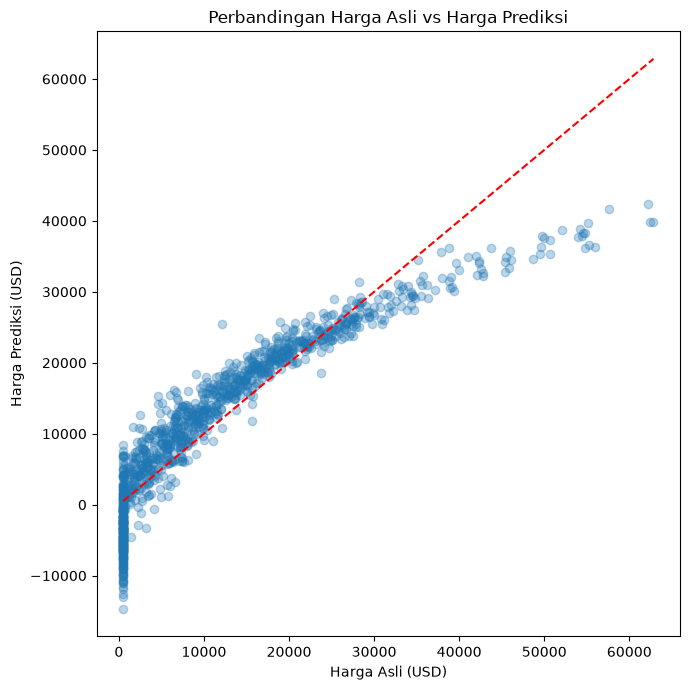

In [23]:
# ============================================================
# Evaluation - Visualisasi Harga Asli vs Harga Prediksi
# ============================================================
# Fungsi      : memplot harga asli (sumbu X) terhadap harga prediksi (sumbu Y) serta
#               menambahkan garis referensi y = x. Semakin dekat titik ke garis tersebut,
#               semakin akurat prediksi model.
# Visualisasi: harga asli vs harga prediksi
plt.figure(figsize=(7, 7))

plt.scatter(y_test.values, y_pred_test, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Harga Asli (USD)')
plt.ylabel('Harga Prediksi (USD)')
plt.title('Perbandingan Harga Asli vs Harga Prediksi')
plt.tight_layout()
plt.show()

# Kesimpulan  : titik-titik mengumpul mengikuti garis diagonal pada rentang harga
#               menengah, yang menandakan prediksi model sudah mendekati harga asli.
#               Sebaran mulai melebar pada harga tinggi, sesuai nilai RMSE 4.810,01 USD.

## **GUI (Graphical User Interface)**

Aplikasi sederhana berbasis Tkinter untuk memprediksi harga wajar mobil bekas berdasarkan spesifikasi yang diinput pengguna.

In [24]:
# ============================================================
# GUI (Graphical User Interface) - Prediksi Harga Mobil Bekas
# ============================================================
# Fungsi      : membangun aplikasi Tkinter agar pengguna dapat memasukkan spesifikasi
#               mobil lalu memperoleh estimasi harga wajar secara langsung.
#               - Entry    : 8 fitur numerik, terisi nilai median sebagai contoh awal
#               - Combobox : 9 fitur kategorikal, berisi daftar kategori unik
#               - prediksi(): menyusun input menjadi satu baris, di-encode dan
#                 distandarisasi memakai mu dan sigma data train, lalu dihitung dengan
#                 koefisien beta sehingga rumusnya konsisten dengan model.
import tkinter as tk
from tkinter import ttk

# Daftar fitur mentah (sebelum encoding)
fitur_raw = df.drop(columns=['Selling_Price', 'Price_Category']).columns

fitur_angka = ['Year', 'Engine_Size', 'Mileage', 'Horsepower', 'Torque',
               'Owners', 'Accident_History', 'Fuel_Efficiency']
fitur_teks = ['Make', 'Model', 'Body_Type', 'Transmission', 'Fuel_Type',
              'Drivetrain', 'Color', 'Location', 'Service_History']


def prediksi(input_user):
    # Susun input menjadi satu baris, lalu encode dengan cara yang sama seperti data training
    baris = pd.DataFrame([input_user])
    gabung = pd.concat([df[fitur_raw], baris], ignore_index=True)
    enc = pd.get_dummies(gabung, columns=kolom_kategorik_enc, drop_first=True, dtype=int)
    enc = enc.reindex(columns=X.columns, fill_value=0)

    # Standardisasi memakai mu & sigma dari data training
    x = np.c_[np.ones(1), (enc.iloc[[-1]].values - mu) / sigma]
    return float((x @ beta).item())


def proses_prediksi():
    try:
        data = {c: float(entry[c].get()) for c in fitur_angka}
        data.update({c: combo[c].get() for c in fitur_teks})
        harga = prediksi(data)
        label_hasil.config(text='Estimasi Harga Wajar: ${:,.2f}'.format(harga))
    except ValueError:
        label_hasil.config(text='Input numerik harus berupa angka!')


root = tk.Tk()
root.title('Auto-Valuation System - Prediksi Harga Mobil Bekas')

entry = {}
combo = {}

for i, c in enumerate(fitur_angka):
    tk.Label(root, text=c, anchor='w').grid(row=i, column=0, sticky='w', padx=8, pady=3)
    entry[c] = tk.Entry(root, width=25)
    entry[c].insert(0, '{:.2f}'.format(df[c].median()))
    entry[c].grid(row=i, column=1, padx=8, pady=3)

offset = len(fitur_angka)
for i, c in enumerate(fitur_teks):
    tk.Label(root, text=c, anchor='w').grid(row=offset + i, column=0, sticky='w', padx=8, pady=3)
    combo[c] = ttk.Combobox(root, values=sorted(df[c].unique().tolist()), width=23)
    combo[c].current(0)
    combo[c].grid(row=offset + i, column=1, padx=8, pady=3)

baris_tombol = offset + len(fitur_teks)
tk.Button(root, text='Prediksi Harga', command=proses_prediksi,
          bg='#2e7d32', fg='white', width=20).grid(row=baris_tombol, column=0, columnspan=2, pady=12)

label_hasil = tk.Label(root, text='Estimasi Harga Wajar: -', font=('Arial', 12, 'bold'))
label_hasil.grid(row=baris_tombol + 1, column=0, columnspan=2, pady=6)

root.mainloop()

# Kesimpulan  : aplikasi menampilkan 17 kolom input (8 numerik + 9 kategorikal) dan hasil
#               estimasi harga. Karena input baru di-encode dan di-reindex ke X.columns
#               memakai mu serta sigma data train, hasil prediksinya konsisten dengan
#               model yang sudah dilatih.

## **Conclusion**

1. **Data Preparation** — Dataset berisi 5.500 baris dan 18 kolom (9 numerik + 9 kategorikal), dengan 7.316 nilai kosong dan 127 nilai `Engine_Size = 0` yang tidak wajar. Nilai kosong ditangani dengan imputasi (median untuk numerik, modus untuk kategorikal) sehingga data menjadi bersih. Tidak ditemukan baris duplikat.

2. **EDA** — Distribusi `Selling_Price` sangat skewed (500 - 86.692 USD) dengan 144 outlier. Deteksi outlier memakai metode **IQR**; 1.166 nilai ekstrem pada fitur numerik ditangani dengan *capping* (winsorizing), sedangkan kolom target sengaja tidak di-capping agar variasi harga asli tetap utuh.

3. **Data Preprocessing** — Dibuat target `Price_Category` (Low / Medium / High) dari `Selling_Price`, dan 9 fitur kategorikal diubah dengan one-hot encoding sehingga dihasilkan 85 fitur numerik siap dilatih.

4. **Modelling** — Multiple Linear Regression diimplementasikan manual tanpa sklearn memakai **Normal Equation**, dengan **pseudo-inverse** untuk mengatasi multikolinearitas antar kolom dummy.

5. **Evaluation** — Model mampu menjelaskan sekitar 84% variasi harga: `R2 = 0.8401`, `Adjusted R2 = 0.8267`, `MAE = 3.696,76 USD`, `MSE = 23.136.199,15`, `RMSE = 4.810,01 USD`. Selisih R2 train (0.8501) dan test (0.8401) kecil sehingga model tidak mengalami overfitting.

6. **GUI** — Aplikasi Tkinter memungkinkan pengguna memasukkan 17 spesifikasi mobil (8 numerik + 9 kategorikal) dan langsung memperoleh estimasi harga wajar.